<a href="https://colab.research.google.com/github/ummugulsumciftci/GROUP30_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CENG313 – Assignment 1: EDA & Baseline
## Kaggle: [Make Data Count – Finding Data References](https://www.kaggle.com/competitions/make-data-count-finding-data-references)
**Group ID:** 30 | **Members:** Ümmügülsüm Çiftçi (C21112022014), Ayça Yalçın (23118080775)

## 1. Problem definition
- **Task:** for every scientific article (PDF; for 400 of the 524 training articles also XML) find all references to
  research datasets – DOIs (e.g. `https://doi.org/10.5061/dryad.xxxx`) or accession IDs (e.g. `GSE12345`).
- **Target variable:** the `type` of each (article, dataset) pair – **Primary** (data produced for this paper) or
  **Secondary** (existing data reused by the paper). Identifiers that are not dataset citations must not be predicted.
- **Evaluation metric:** F1 score over unique `(article_id, dataset_id, type)` tuples; a prediction counts only if
  both the identifier and its type are correct.
- **Why it is not a standard tabular task:** the inputs are full-text documents, so candidates must first be
  extracted from the text (information extraction) and then classified. Our reusable code is in `src/`.

### Setup
The first cell clones our repository so that the code in `src/` can be imported; the second downloads the
competition data with the Kaggle API into `/content/data` (the data is never committed); the third imports our
functions and sets one colour per class for all plots.

In [1]:
import os, sys, subprocess

GITHUB_USER = "ummugulsumciftci"
REPO_DIR = "GROUP30_CENG313"
REPO_PATH = f"/content/{REPO_DIR}"

if not os.path.exists(REPO_PATH):
    url = f"https://github.com/{GITHUB_USER}/{REPO_DIR}.git"
    try:  # private repo -> token from Colab secrets
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{GITHUB_USER}/{REPO_DIR}.git"
    except Exception:
        pass  # public repo
    subprocess.run(["git", "clone", "-q", url, REPO_PATH], check=True)
else:
    subprocess.run(["git", "pull", "-q"], cwd=REPO_PATH)  # get the latest src/ changes

os.chdir(REPO_PATH)
sys.path.insert(0, REPO_PATH)
!pip install -q pymupdf
print("src files:", os.listdir("src"))

src files: ['models.py', 'data.py', 'utils.py', '__init__.py']


In [4]:
#data load
import os

if not os.path.exists("/content/data/train_labels.csv"):
    from google.colab import files
    uploaded = files.upload()                        # choose kaggle.json
    fname = list(uploaded.keys())[0]                 # real name, e.g. "kaggle (1).json"
    os.makedirs("/root/.kaggle", exist_ok=True)
    os.replace(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    !kaggle competitions download -c make-data-count-finding-data-references -p /content
    !unzip -q -o /content/make-data-count-finding-data-references.zip -d /content/data
print(os.listdir("/content/data"))

Saving kaggle (1).json to kaggle (1).json
100% 1.76G/1.76G [00:23<00:00, 80.5MB/s]

['test', 'train', 'train_labels.csv', 'sample_submission.csv']


In [5]:
#settings
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from src.data import Paths, find_data_dir, load_labels, scored_labels, list_articles, load_texts, reference_start
from src.utils import build_candidates, attach_gold, doi_prefix, accession_family, set_seed

set_seed(42)
pd.set_option("display.max_colwidth", 120)

# one colour per meaning, used in every chart
C = {"Primary": "#2a78d6", "Secondary": "#eb6834", "None": "#9a9890", "bar": "#2a78d6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110, "axes.titleweight": "bold"})

paths = Paths(find_data_dir())
print("data dir:", paths.root)

data dir: /content/data


## 2. Data overview
### 2.1 Files

In [6]:
train_art = list_articles(paths, "train")
test_art = list_articles(paths, "test")
inv = pd.DataFrame({
    split: {"articles": len(a), "with PDF": int(a.has_pdf.sum()), "with XML": int(a.has_xml.sum()),
            "PDF and XML": int((a.has_pdf & a.has_xml).sum())}
    for split, a in [("train", train_art), ("test", test_art)]})
inv

,train,test
articles,524,30
with PDF,524,30
with XML,400,25
PDF and XML,400,25


In [7]:
overlap = set(test_art.article_id) & set(train_art.article_id)
print("visible test articles that are also in train:", len(overlap), "/", len(test_art))

visible test articles that are also in train: 30 / 30


*Interpretation:* the training set contains 524 articles; all of them have a PDF and 400 (76 %) also have an XML
version. The visible test set has 30 articles, and all 30 also appear in the training set, so it only shows the
submission format – the real test set is hidden and used when the notebook is scored on Kaggle. Because XML text is
cleaner (no line breaks inside identifiers), we use both sources.

### 2.2 Label table: shape, types, describe(), missing values, duplicates

In [8]:
raw = pd.read_csv(paths.labels)          # the original label file, before our preprocessing
print("train_labels.csv shape:", raw.shape)
display(raw.dtypes.to_frame("dtype"))
display(raw.describe(include="all"))
display(raw.isna().sum().to_frame("missing values"))
print("duplicate rows:", raw.duplicated().sum())
print("duplicate (article_id, dataset_id) pairs:", raw.duplicated(["article_id", "dataset_id"]).sum())

sample = pd.read_csv(paths.sample_submission)
print("\nsample_submission.csv shape:", sample.shape)
display(sample.head())

train_labels.csv shape: (1066, 3)


,dtype
article_id,object
dataset_id,object
type,object


,article_id,dataset_id,type
count,1066,1066,1066
unique,523,1066,3
top,10.3390_v11060565,https://doi.org/10.17882/49388,Secondary
freq,32,1,449


,missing values
article_id,0
dataset_id,0
type,0


duplicate rows: 0
duplicate (article_id, dataset_id) pairs: 0

sample_submission.csv shape: (14, 4)


,row_id,article_id,dataset_id,type
0,0,10.1002_2017jc013030,https://doi.org/10.17882/49388,Primary
1,1,10.1002_cssc.202201821,https://doi.org/10.5281/zenodo.7074790,Primary
2,2,10.1002_ece3.4466,https://doi.org/10.5061/dryad.r6nq870,Primary
3,3,10.1002_ece3.5260,https://doi.org/10.5061/dryad.2f62927,Primary
4,4,10.1002_ece3.6144,https://doi.org/10.5061/dryad.zw3r22854,Primary


*Interpretation:* `train_labels.csv` has 1066 rows and 3 columns, all strings (`object`): `article_id`, `dataset_id`
and `type`. `describe()` shows 523 unique articles (the most frequent one, 10.3390_v11060565, has 32 rows), 1066
unique dataset IDs – every identifier occurs only once, so no dataset is cited by two training articles – and 3
values of `type` (Primary, Secondary, Missing); the most frequent is Secondary (449 rows). There are no missing
values and no duplicate rows (0 duplicate article–dataset pairs); even the "Missing" rows have a `dataset_id`
(Section 3.1). The table contains only the labels: the information needed to predict them is in the article texts
(PDF/XML), so the modelling table is built by text extraction (Sections 3.4–3.6). `sample_submission.csv` has 14 rows
with the same three columns plus `row_id`.

## 3. Exploratory data analysis
### 3.1 Target balance and "Missing" labels

In [9]:
labels = load_labels(paths)
gold = scored_labels(labels)            # rows used by the metric (no 'Missing')
print("label rows:", len(labels), "| articles in labels:", labels.article_id.nunique())
print("scored tuples (without Missing):", len(gold))
labels.head(10)

label rows: 1066 | articles in labels: 523
scored tuples (without Missing): 719


,article_id,dataset_id,type,dataset_id_raw,is_missing,id_kind
0,10.1002_2017jc013030,https://doi.org/10.17882/49388,Primary,https://doi.org/10.17882/49388,False,DOI
1,10.1002_anie.201916483,https://doi.org/10.5517/ccdc.csd.cc1npvt0,Missing,https://doi.org/10.5517/ccdc.csd.cc1npvt0,True,Missing
2,10.1002_anie.202005531,https://doi.org/10.5517/ccdc.csd.cc24wxqp,Missing,https://doi.org/10.5517/ccdc.csd.cc24wxqp,True,Missing
3,10.1002_anie.202007717,https://doi.org/10.5517/ccdc.csd.cc24rrb0,Missing,https://doi.org/10.5517/ccdc.csd.cc24rrb0,True,Missing
4,10.1002_chem.201902131,https://doi.org/10.5517/ccdc.csd.cc221dk3,Missing,https://doi.org/10.5517/ccdc.csd.cc221dk3,True,Missing
5,10.1002_chem.201903120,https://doi.org/10.5517/ccdc.csd.cc22c4yk,Missing,https://doi.org/10.5517/ccdc.csd.cc22c4yk,True,Missing
6,10.1002_chem.202000235,https://doi.org/10.5517/ccdc.csd.cc24cjxz,Missing,https://doi.org/10.5517/ccdc.csd.cc24cjxz,True,Missing
7,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsk5,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsk5,True,Missing
8,10.1002_chem.202001412,https://doi.org/10.5517/ccdc.csd.cc24nsqb,Missing,https://doi.org/10.5517/ccdc.csd.cc24nsqb,True,Missing
9,10.1002_chem.202001668,https://doi.org/10.5517/ccdc.csd.cc24d93z,Missing,https://doi.org/10.5517/ccdc.csd.cc24d93z,True,Missing


In [10]:
art_status = labels.groupby("article_id")["is_missing"].all().map({True: "no dataset (Missing)", False: ">=1 dataset"})
print(art_status.value_counts(), "\n")
print(gold["type"].value_counts(), "\n")
print("PDFs without any label row:", len(set(train_art.article_id) - set(labels.article_id)))
print("same (article, dataset) with two different types:", gold.duplicated(["article_id", "dataset_id"], keep=False).sum())

is_missing
no dataset (Missing)    309
>=1 dataset             214
Name: count, dtype: int64 

type
Secondary    449
Primary      270
Name: count, dtype: int64 

PDFs without any label row: 1
same (article, dataset) with two different types: 0


In [11]:
miss = labels[labels.is_missing].copy()
miss["prefix"] = miss.dataset_id_raw.map(doi_prefix)
print("Missing rows:", len(miss), "| with a DOI:", miss.prefix.notna().sum())
miss.prefix.value_counts().head(10)

Missing rows: 347 | with a DOI: 343


,count
prefix,
10.6084,223
10.5517,75
10.17182,23
10.15468,8
10.25592,4
10.5061,3
10.1594,2
10.5441,1
10.11583,1


*Interpretation:* 309 of 523 labelled articles (59 %) have no counted dataset. However, 343 of the 347 "Missing"
rows still contain a DOI, mostly figshare (10.6084, 223 rows) and CCDC crystal structures (10.5517, 75 rows). These
identifiers are mentioned in the articles but are not counted as dataset citations (typically supplementary
material), so "Missing" means "no counted dataset", not "no identifier": even repository DOIs cannot be accepted
blindly.

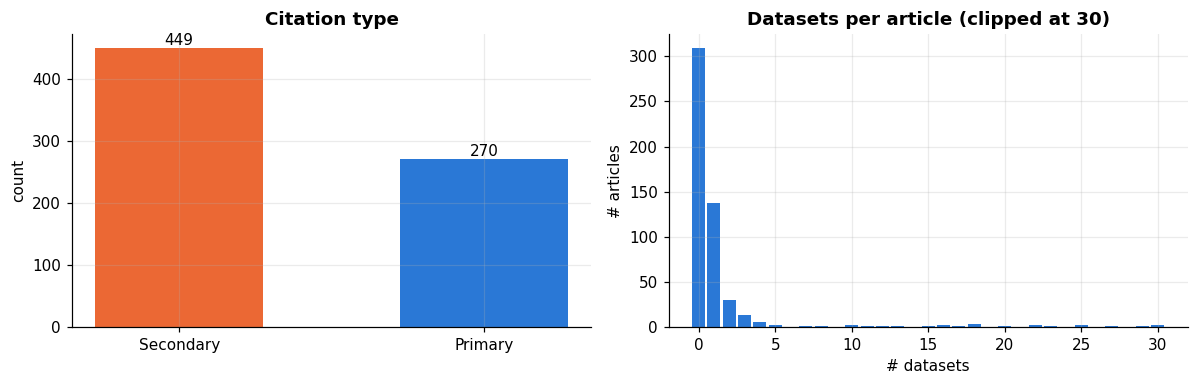

count    523.00
mean       1.37
std        4.15
min        0.00
25%        0.00
50%        0.00
75%        1.00
max       32.00
dtype: float64


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = gold["type"].value_counts()
ax[0].bar(vc.index, vc.values, color=[C[t] for t in vc.index], width=.55)
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v}", ha="center", va="bottom")
ax[0].set_title("Citation type"); ax[0].set_ylabel("count")

per_art = gold.groupby("article_id").size().reindex(labels.article_id.unique(), fill_value=0)
bins = np.arange(0, min(per_art.max(), 30) + 2) - .5
ax[1].hist(per_art.clip(upper=30), bins=bins, color=C["bar"], rwidth=.85)
ax[1].set_title("Datasets per article (clipped at 30)"); ax[1].set_xlabel("# datasets"); ax[1].set_ylabel("# articles")
plt.tight_layout(); plt.show()
print(per_art.describe().round(2))

*Interpretation:* the target is imbalanced: 449 Secondary (62 %) vs. 270 Primary (38 %) citations. The number of
datasets per article is highly right-skewed (median 0, mean 1.37, max 32): most articles cite no or one dataset.

In [13]:
top_art = gold.article_id.value_counts()
print(top_art.head(10))
print("share of all tuples in the 10 largest articles:", round(top_art.head(10).sum() / len(gold), 3))

article_id
10.3390_v11060565               32
10.1038_s41396-020-00885-8      31
10.1128_spectrum.00422-24       29
10.1371_journal.pone.0159387    27
10.1371_journal.pone.0212669    25
10.7717_peerj.10452             25
10.1111_cas.12935               23
10.1128_JVI.01717-21            22
10.1371_journal.pcbi.1011828    22
10.1038_s41598-020-59839-x      20
Name: count, dtype: int64
share of all tuples in the 10 largest articles: 0.356


*Interpretation (outliers):* the 10 largest articles contain 35.6 % of all scored citations; articles with 20–32
datasets are clear outliers. We keep them because they are real citations, but they are the reason why validation
must split by article (GroupKFold): otherwise mentions of the same article would leak between train and validation.

### 3.2 Relationship between identifier kind and target

type,Primary,Secondary
id_kind,,
Accession,55,339
DOI,215,110


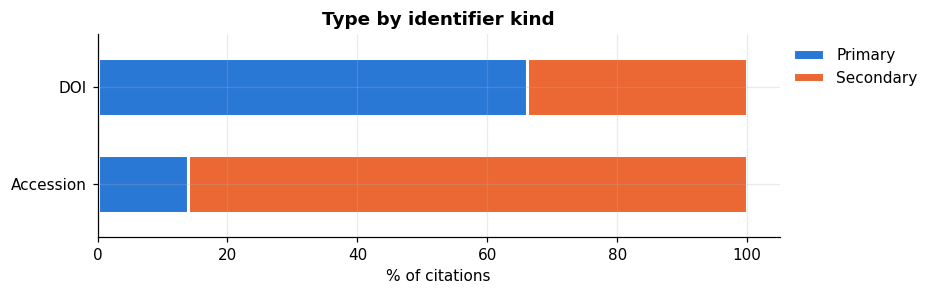

In [14]:
gold["id_kind"] = np.where(gold.dataset_id.str.contains(r"10\.\d{4,9}/"), "DOI", "Accession")
ct = pd.crosstab(gold.id_kind, gold.type)
display(ct)

ax = (ct.div(ct.sum(1), axis=0) * 100).plot.barh(stacked=True, figsize=(8, 2.4),
        color=[C[c] for c in ct.columns], width=.6, edgecolor="white", linewidth=2)
ax.set_xlabel("% of citations"); ax.set_ylabel(""); ax.set_title("Type by identifier kind")
ax.legend(frameon=False, bbox_to_anchor=(1, 1)); plt.show()

*Interpretation:* the identifier kind is the strongest single signal for the target: 66 % of DOIs are Primary
(215/325), while 86 % of accession IDs are Secondary (339/394). Repository DOIs are typically used for data
deposited by the authors; accession IDs usually refer to existing database records. This motivates the baseline.

### 3.3 Repositories and databases

distinct DOI prefixes: 49


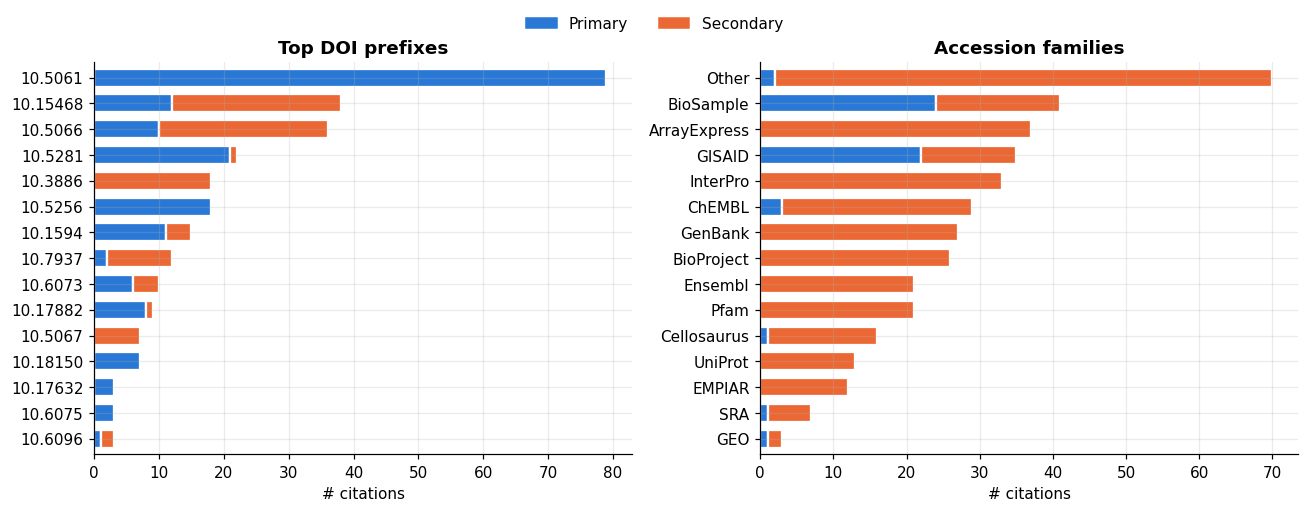

accessions not matched by our regexes: 70


,article_id,dataset_id,type,id_kind,family
40,10.1021_acsomega.3c06074,5VA1,Secondary,Accession,Other
149,10.1038_s41598-024-56373-y,STH00996,Secondary,Accession,Other
196,10.1093_nar_gkp1049,3.10.180.10,Secondary,Accession,Other
197,10.1093_nar_gkp1049,3.20.20.120,Secondary,Accession,Other
198,10.1093_nar_gkp1049,3.20.20.140,Secondary,Accession,Other
199,10.1093_nar_gkp1049,3.30.450.20,Secondary,Accession,Other
200,10.1093_nar_gkp1049,3.30.450.40,Secondary,Accession,Other
201,10.1093_nar_gkp1049,3.30.930.10,Secondary,Accession,Other
202,10.1093_nar_gkp1049,3.40.30.10,Secondary,Accession,Other
203,10.1093_nar_gkp1049,3.40.50.1000,Secondary,Accession,Other


In [15]:
dois = gold[gold.id_kind == "DOI"].copy()
dois["prefix"] = dois.dataset_id.map(doi_prefix)
top = pd.crosstab(dois.prefix, dois.type)
top = top.loc[top.sum(1).sort_values(ascending=False).index[:15]]

acc = gold[gold.id_kind == "Accession"].copy()
acc["family"] = acc.dataset_id.map(accession_family)
fam = pd.crosstab(acc.family, acc.type)
fam = fam.loc[fam.sum(1).sort_values(ascending=False).index[:15]]
print("distinct DOI prefixes:", dois.prefix.nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, tab, title in [(ax[0], top, "Top DOI prefixes"), (ax[1], fam, "Accession families")]:
    tab[::-1].plot.barh(stacked=True, ax=a, color=[C[c] for c in tab.columns], width=.7,
                        edgecolor="white", linewidth=1.5, legend=False)
    a.set_title(title); a.set_ylabel(""); a.set_xlabel("# citations")
fig.legend(handles=[Patch(color=C[t], label=t) for t in ["Primary", "Secondary"]],
           frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.04))
plt.tight_layout(); plt.show()

print("accessions not matched by our regexes:", (acc.family == "Other").sum())
acc[acc.family == "Other"].head(15)

In [16]:
other = acc[acc.family == "Other"].copy()
other["prefix"] = other.dataset_id.str.extract(r"^([A-Za-z_]+)")[0].fillna("(digits)")
other.groupby("prefix")["dataset_id"].agg(n="size", examples=lambda s: ", ".join(s.head(3)))\
     .sort_values("n", ascending=False)

,n,examples
prefix,,
EPI,29,"EPI1018205, EPI1018206, EPI1018207"
(digits),18,"5VA1, 3.10.180.10, 3.20.20.120"
PXD,10,"PXD001676, PXD002137, PXD005693"
HPA,9,"HPA001426, HPA001522, HPA001612"
CAB,2,"CAB004592, CAB010055"
MODEL,1,MODEL2106070001
STH,1,STH00996


*Interpretation:* dataset DOIs come from 49 different registrants, and a few repositories dominate (Dryad 10.5061,
Zenodo 10.5281, …; see chart). 70 accession IDs (18 %) are not covered by our regexes, mainly GISAID EPI IDs (29),
CATH codes / bare PDB codes (18), PRIDE PXD (10) and Human Protein Atlas HPA/CAB IDs (11). PDB codes without the
word "PDB" (e.g. 5VA1) are not matched on purpose, because a bare 4-character pattern would create too much noise.

### 3.4 Text extraction and text length

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


100/524 articles, 16s
200/524 articles, 30s
300/524 articles, 46s
MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: cannot create appearance stream for  annotations

MuPDF error: unsupported error: 

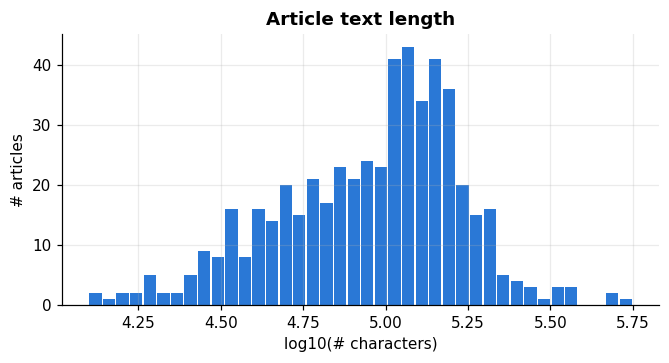

In [17]:
t0 = time.time()
train_texts = load_texts(train_art, source="both", cache_path="/content/train_texts.json")
print(f"{len(train_texts)} articles in {time.time() - t0:.0f}s")
train_art["n_chars"] = train_art.article_id.map(lambda a: len(train_texts[a]))
print(train_art.n_chars.describe().round(0))
print("empty texts:", (train_art.n_chars == 0).sum())

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.log10(train_art.n_chars.clip(lower=1)), bins=40, color=C["bar"], rwidth=.9)
ax.set_xlabel("log10(# characters)"); ax.set_ylabel("# articles"); ax.set_title("Article text length")
plt.show()

*Interpretation (outliers):* text extraction of 524 articles takes about one minute and returns no empty text.
Text length is right-skewed (median ≈ 103k, max 561k characters); the longest articles are outliers with large
supplementary tables and produce many noisy candidates. We keep them because the hidden test set will contain such
articles as well.

### 3.5 Can the labelled identifiers be found in the text?

In [18]:
def found_in_text(row):
    text = train_texts.get(row.article_id, "").lower()
    return row.dataset_id.replace("https://doi.org/", "").lower() in text

gold["found"] = gold.apply(found_in_text, axis=1)
print(gold.groupby(["id_kind", "type"])["found"].mean().round(3))
print("\nshare of gold ids present in the text:", round(gold.found.mean(), 3))
gold[~gold.found].head(10)

id_kind    type     
Accession  Primary      1.000
           Secondary    1.000
DOI        Primary      0.837
           Secondary    0.964
Name: found, dtype: float64

share of gold ids present in the text: 0.946


,article_id,dataset_id,type,id_kind,found
19,10.1016_j.ast.2022.107401,https://doi.org/10.17862/cranfield.rd.19146182,Primary,DOI,False
20,10.1016_j.ast.2022.107401,https://doi.org/10.17862/cranfield.rd.19146182.v1,Primary,DOI,False
21,10.1016_j.cpc.2024.109087,https://doi.org/10.17632/9gr6pxhfjm,Primary,DOI,False
24,10.1016_j.ecolind.2021.107934,https://doi.org/10.6073/pasta/be42bb841e696b7bcad9957aed33db5e,Secondary,DOI,False
26,10.1016_j.fuel.2022.125768,https://doi.org/10.11583/dtu.20555586.v3,Primary,DOI,False
27,10.1016_j.jlp.2022.104761,https://doi.org/10.23642/usn.15134442,Primary,DOI,False
28,10.1016_j.jlp.2022.104761,https://doi.org/10.23642/usn.15134442.v1,Primary,DOI,False
29,10.1016_j.jobe.2023.107105,https://doi.org/10.5281/zenodo.8014149,Primary,DOI,False
38,10.1021_acs.jcim.9b01185,https://doi.org/10.5281/zenodo.3667633,Primary,DOI,False
52,10.1021_jacs.2c06519,https://doi.org/10.25377/sussex.21184705.v1,Primary,DOI,False


In [19]:
import re
for _, r in gold[~gold.found].head(8).iterrows():
    key = (re.findall(r"\d{5,}", r.dataset_id) or [r.dataset_id[-8:]])[-1]   # longest number in the id
    t = train_texts[r.article_id]
    i = t.lower().find(key.lower())
    print(r.dataset_id, "\n   ->", repr(t[max(0, i - 80):i + 40]) if i >= 0 else "not in text at all", "\n")

https://doi.org/10.17862/cranfield.rd.19146182 
   -> ' by Damiano Casalino Dataset link: https:// doi .org /10 .17862 /cranfield .rd .19146182 .v1 Keywords: High-order method' 

https://doi.org/10.17862/cranfield.rd.19146182.v1 
   -> ' by Damiano Casalino Dataset link: https:// doi .org /10 .17862 /cranfield .rd .19146182 .v1 Keywords: High-order method' 

https://doi.org/10.17632/9gr6pxhfjm 
   -> not in text at all 

https://doi.org/10.6073/pasta/be42bb841e696b7bcad9957aed33db5e 
   -> 'a are avail able online (https://doi.org/10.6073/pasta/be42bb841e696b7bca d9957aed33db5e). Ocean-sea ice model output ar' 

https://doi.org/10.11583/dtu.20555586.v3 
   -> 'he results is freely available in a repository at: https://doi.org/10.11583/DTU.20555586.v2. Acknowledgments The authors' 

https://doi.org/10.23642/usn.15134442 
   -> 'r Channel Partly Filled with 18650 Cell Geometry. https://doi.org/10.23642/ USN.15134442.V1. Henriksen, M., Vaagsaether,' 

https://doi.org/10.23642/usn.15134442

*Interpretation:* 94.6 % of the gold identifiers appear literally in the extracted text (accessions 100 %, Secondary
DOIs 96 %, Primary DOIs only 84 %). The examples show why: some PDFs insert spaces inside DOIs
("10 .17862 /cranfield .rd"), line breaks split them, the version differs between text and label (v2 vs v3), and
a few DOIs are not in the extracted text at all. The labels also list a DOI and its versioned form (".v1") as two
separate citations.

### 3.6 Regex candidates

In [20]:
cands = build_candidates(train_texts, window=250, ref_start_fn=reference_start)
cands = cands[cands.article_id.isin(labels.article_id)]
lab_c = attach_gold(cands, gold)
uniq = lab_c.drop_duplicates(["article_id", "dataset_id"])
print(f"mentions: {len(cands)} | unique (article, id) candidates: {len(uniq)}")
summary = (uniq.groupby(["kind", "pattern"])["label"]
               .agg(n="size", datasets=lambda s: (s != "None").sum())
               .assign(precision=lambda d: (d.datasets / d.n).round(3))
               .sort_values("n", ascending=False))
summary.head(25)

mentions: 32702 | unique (article, id) candidates: 20416


n  datasets  precision
kind      pattern                            
DOI       10.1016   2956         0      0.000
          10.1038   1573         0      0.000
          10.1111   1229         0      0.000
          10.1093   1133         0      0.000
          10.1007   1069         0      0.000
          10.1002    935         0      0.000
          10.1371    724         0      0.000
Accession GenBank    693        27      0.039
DOI       10.1186    664         0      0.000
          10.1021    495         0      0.000
          10.1029    392         0      0.000
          10.1073    357         0      0.000
          10.1126    352         0      0.000
          10.5194    314         0      0.000
          10.13039   265         0      0.000
          10.1128    260         0      0.000
          10.1175    192         0      0.000
          10.1101    185         0      0.000
          10.1039    178         0      0.000
          10.3389    177         0      0.000
          10.1080    176         0      0.000
Accession UniProt    171        13      0.076
DOI       10.1107    147         0      0.000
          10.3390    145         0      0.000
          10.1098    138         0      0.000

In [21]:
cand_pairs = set(zip(uniq.article_id, uniq.dataset_id))
gold_pairs = set(zip(gold.article_id, gold.dataset_id))
print("recall upper bound (gold ids found by regex):", round(len(cand_pairs & gold_pairs) / len(gold_pairs), 3))
print("raw precision (if we predicted every candidate):", round((uniq.label != "None").mean(), 3))

recall upper bound (gold ids found by regex): 0.826
raw precision (if we predicted every candidate): 0.029


*Interpretation:* the regexes produce 20,416 unique candidates, but only 2.9 % are real dataset citations. Publisher
DOI prefixes (10.1016, 10.1038, 10.1111, …) never contain a dataset, and broad accession patterns such as GenBank
(3.9 %) and UniProt (7.6 %) are very noisy. The candidates cover 82.6 % of the gold citations – the recall ceiling of
this approach. The main problem is therefore filtering the candidates; the type comes second.

### 3.7 Where in the paper do citations occur?

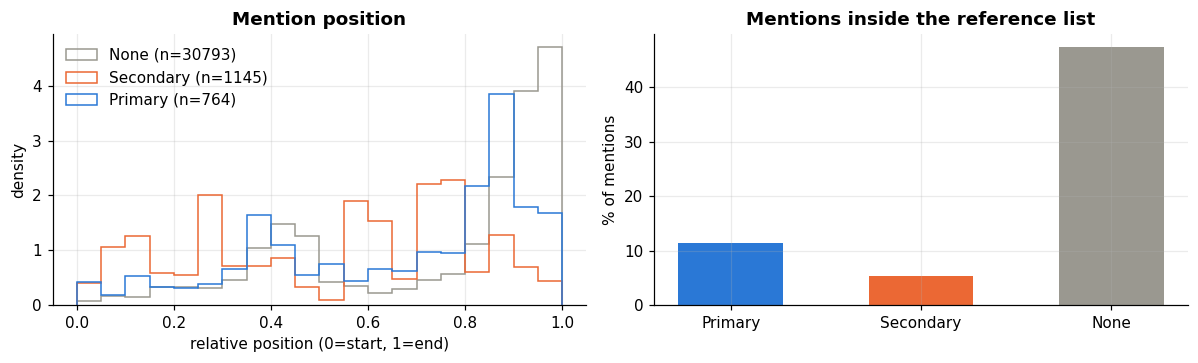

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for lbl in ["None", "Secondary", "Primary"]:
    sub = lab_c[lab_c.label == lbl]
    ax[0].hist(sub.rel_pos, bins=20, range=(0, 1), histtype="step", lw=2, color=C[lbl], density=True,
               label=f"{lbl} (n={len(sub)})", ls="--" if lbl == "None" else "-")
ax[0].set_xlabel("relative position (0=start, 1=end)"); ax[0].set_ylabel("density")
ax[0].set_title("Mention position"); ax[0].legend(frameon=False)

ref = lab_c.groupby("label")["in_references"].mean().reindex(["Primary", "Secondary", "None"])
ax[1].bar(ref.index, ref.values * 100, color=[C[k] for k in ref.index], width=.55)
ax[1].set_ylabel("% of mentions"); ax[1].set_title("Mentions inside the reference list")
plt.tight_layout(); plt.show()

*Interpretation:* 47 % of the non-dataset candidates are inside the reference list, compared to 11 % of Primary and
5 % of Secondary mentions, so the reference-list position is a useful filter. Primary citations peak at a relative
position of about 0.85–0.9 (data availability statement just before the references), with a smaller peak in the
methods; Secondary citations are spread over the methods and results.
*Limitation:* for the 400 articles with XML, the text is PDF text followed by XML text, so positions are compressed
and only the reference list of the second copy is detected.

### 3.8 Context words: Primary vs. Secondary

In [23]:
from sklearn.feature_extraction.text import CountVectorizer

ds = lab_c[lab_c.label.isin(["Primary", "Secondary"])]
# one document per (article, label): a word counts once per article, so a single article cannot dominate
docs = ds.groupby(["article_id", "label"])["context"].apply(" ".join).reset_index()
cv = CountVectorizer(stop_words="english", min_df=5, binary=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X = cv.fit_transform(docs.context)
vocab = np.array(cv.get_feature_names_out())
p = np.asarray(X[(docs.label == "Primary").values].sum(0)).ravel() + 1
s = np.asarray(X[(docs.label == "Secondary").values].sum(0)).ravel() + 1
log_ratio = np.log((p / p.sum()) / (s / s.sum()))
order = np.argsort(log_ratio)
pd.DataFrame({"Secondary-leaning": vocab[order[:20]], "Primary-leaning": vocab[order[::-1][:20]]})

,Secondary-leaning,Primary-leaning
0,average,dryad
1,acc,accessibility
2,family,material
3,annotated,foundation
4,like,thank
5,ice,supported
6,binding,commons
7,map,acknowledgements
8,proteins,orcid
9,respectively,digital


In [24]:
for t in ["Primary", "Secondary"]:
    print(f"===== {t} examples =====")
    for ctx in ds[ds.label == t].sample(3, random_state=1).context:
        print("...", ctx[150:400], "...\n")

===== Primary examples =====
... 4 in: Cryopreservation of orchid seeds through rapid and step freezing methods. F1000Research. 2018 10.5256/f1000research.13622.d194236 10.5256/f1000research.14799.r33998 Referee response for version 1 Hunyadi Éva Borbélyné 1 Referee 1 Research Insti ...

... ons are available in Supplementary Material of this article available on Dryad at http://dx.doi.org/10.5061/dryad.739bs, Appendix S1. Scenario I.-We began simulations with the null scenario of a single, unstructured population or species (Fig. 1a), u ...

... m.nih.gov/biosample/SAMN16233656 SAMN16233656 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233657 SAMN16233657 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233658 SAMN16233658 , https://www.ncbi.nlm.nih.gov/biosample/SAMN16233659 SAMN16233659 , h ...

===== Secondary examples =====
... ign="char" char="." rowspan="1" colspan="1">0</td></tr><tr><td align="left" rowspan="1" colspan="1">P24821</td><td align="left" rowspan="1" colspan="1">Tena

*Interpretation:* counting each word once per article, Primary contexts contain data-availability and
acknowledgement words (dryad, deposited, repository, accessibility, collected, orcid, creative commons), matching
the position peak at the end of the paper. Secondary contexts contain domain and method words (protein, binding,
annotated, family, satellite, grid), where existing databases are used. The examples also show noise: HTML table
markup from the XML files (rowspan/colspan) and label noise (an F1000 referee-report DOI labelled Primary).

### EDA summary
1. 59 % of the labelled articles have no counted dataset; the target is imbalanced (62 % Secondary, 38 % Primary).
2. A few outlier articles (up to 32 datasets) contain 36 % of all citations → validation by article.
3. The identifier kind is the strongest signal: 66 % of DOIs are Primary, 86 % of accession IDs are Secondary.
4. "Missing" rows still carry identifiers (figshare, CCDC) → a repository alone is not enough.
5. 94.6 % of gold IDs are in the text, our regexes reach 82.6 % (recall ceiling).
6. Only 2.9 % of candidates are datasets → filtering is the main problem.
7. Primary citations are in data availability statements, Secondary ones in methods/results.

## 4. Preprocessing
All steps are implemented in `src/data.py` and `src/utils.py` and are used by both the EDA and the baseline.

| Step | What we do | Why |
|---|---|---|
| Text extraction | PDF text with PyMuPDF (pypdf as fallback, broken pages skipped) + all text nodes and `href` links of the XML | the labels must be found in the full text; XML is cleaner, the PDF covers all articles |
| Cleaning | Unicode NFKC, unify dashes, remove soft hyphens, collapse whitespace | identifiers must match the labels character by character |
| Line-break repair | glue DOIs broken at a line end, remove hyphen + line break | Section 3.5 showed DOIs split by layout |
| Identifier normalisation | DOIs → `https://doi.org/<lower-case doi>`; strip trailing punctuation and unbalanced brackets | the labels use this format; the metric compares strings exactly |
| Label cleaning | `Missing` rows removed from the scored set, duplicate rows dropped | `Missing` is not a class of the metric (Section 3.1) |
| Candidate generation | regex for DOIs + 18 accession families, the article's own DOI removed, ±250 characters of context kept | turns free text into a table of candidates that can be filtered and classified |
| Imputation | not needed: the label file has no missing values; articles without XML simply use the PDF text | – |
| Encoding / scaling | B0 uses only two categorical features (identifier kind, repository) as group keys, so no encoding or scaling is needed; Assignment 2 will encode the context with TF-IDF | the task has no numeric features to scale |

In [25]:
from src.utils import normalize_doi
from src.data import clean_text

examples = ["doi:10.5061/DRYAD.X.", "https://dx.doi.org/10.5281/zenodo.123)", "see 10.5061/dryad.\n7890ab here"]
for e in examples:
    found = [normalize_doi(m) for m in re.findall(r"10\.\d{4,9}/\S+", clean_text(e))]
    print(repr(e), "->", found)

'doi:10.5061/DRYAD.X.' -> ['https://doi.org/10.5061/dryad.x']
'https://dx.doi.org/10.5281/zenodo.123)' -> ['https://doi.org/10.5281/zenodo.123']
'see 10.5061/dryad.\n7890ab here' -> ['https://doi.org/10.5061/dryad.7890ab']


*Interpretation:* differently written DOIs (prefix, upper case, trailing dot, closing bracket, line break) are all
mapped to the exact label format. Without this step correct predictions would not match the labels.

## 5. Baseline model – B0: regex + majority class
**Model:** a simple rule-based classifier learned from the training data:
1. *Candidates:* all regex matches (DOIs + accession IDs) of an article (Section 3.6).
2. *Filter:* on the training folds B0 learns which DOI prefixes / accession families really are datasets
   (≥ 5 % of their candidates are labelled datasets) and drops all other candidates.
3. *Type:* every kept candidate gets the most frequent type of its identifier kind in the training folds.

**Validation:** 5-fold GroupKFold by article = five train/validation splits (80 % / 20 % of the articles each, an
article is never in both). We report the competition F1 on the out-of-fold predictions and the per-fold F1.
The **oracle** row is not a model: it is a perfect classifier on the same candidates (upper bound).

In [26]:
from src.models import RegexMajorityBaseline, oracle_predictions, cross_validate
from src.utils import f1_tuples, make_submission

train_ids = sorted(labels.article_id.unique())
t0 = time.time()
r = cross_validate(RegexMajorityBaseline, cands, gold, train_ids, n_splits=5)
oof_b0 = r.pop("oof")                                   # out-of-fold predictions
oracle = oracle_predictions(cands, gold)

res = pd.DataFrame([{"model": "B0 regex + majority", **r, "time_s": round(time.time() - t0, 1)}]).set_index("model")
res.loc["Oracle (upper bound)"] = f1_tuples(oracle, gold)
res.round(3)

,precision,recall,f1,tp,fp,fn,f1_fold_mean,f1_fold_std,time_s
model,,,,,,,,,
B0 regex + majority,0.265,0.410,0.322,295,818,424,0.321,0.087,0.5
Oracle (upper bound),1.000,0.826,0.905,594,0,125,NaN,NaN,NaN


*Interpretation:* B0 reaches **F1 = 0.322** on the validation folds (precision 0.265, recall 0.410; per-fold F1
0.321 ± 0.087). The oracle on the same candidates reaches F1 = 0.905 (recall 0.826), so most of the loss comes from
the classification step, not from candidate extraction.

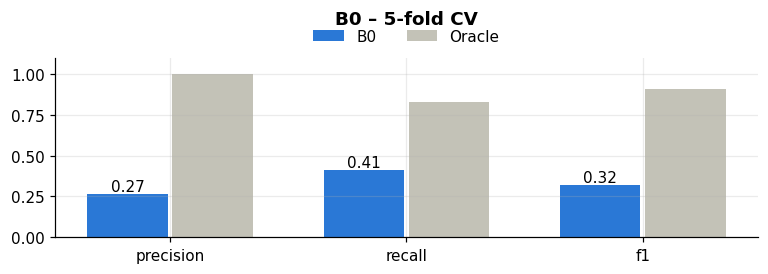

In [27]:
fig, ax = plt.subplots(figsize=(7, 2.6))
metrics = ["precision", "recall", "f1"]
x = np.arange(len(metrics))
ax.bar(x - .18, res.loc["B0 regex + majority", metrics], width=.34, color="#2a78d6", label="B0")
ax.bar(x + .18, res.loc["Oracle (upper bound)", metrics], width=.34, color="#c3c2b7", label="Oracle")
for i, v in enumerate(res.loc["B0 regex + majority", metrics]):
    ax.text(i - .18, v, f"{v:.2f}", ha="center", va="bottom")
ax.set_xticks(x, metrics); ax.set_ylim(0, 1.1); ax.set_title("B0 – 5-fold CV", pad=22)
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5, 1.0))
plt.tight_layout(); plt.show()

*Interpretation:* precision is the weakest metric of B0: most of its predictions are not real citations. The gap to
the oracle in every metric shows how much a better filter and type classifier can gain.

In [28]:
b0_full = RegexMajorityBaseline().fit(cands, gold)     # fit on all training articles
print("majority type per kind:", b0_full.majority_)
print("kept (kind, pattern) groups:", len(b0_full.keep_patterns_))
sorted(b0_full.keep_patterns_)

majority type per kind: {'Accession': 'Secondary', 'DOI': 'Primary'}
kept (kind, pattern) groups: 56


[('Accession', 'ArrayExpress'),
 ('Accession', 'BioProject'),
 ('Accession', 'BioSample'),
 ('Accession', 'Cellosaurus'),
 ('Accession', 'ChEMBL'),
 ('Accession', 'EMPIAR'),
 ('Accession', 'Ensembl'),
 ('Accession', 'GISAID'),
 ('Accession', 'InterPro'),
 ('Accession', 'Pfam'),
 ('Accession', 'SRA'),
 ('Accession', 'UniProt'),
 ('DOI', '10.11588'),
 ('DOI', '10.13012'),
 ('DOI', '10.13020'),
 ('DOI', '10.15125'),
 ('DOI', '10.15131'),
 ('DOI', '10.15468'),
 ('DOI', '10.15482'),
 ('DOI', '10.15485'),
 ('DOI', '10.1594'),
 ('DOI', '10.17632'),
 ('DOI', '10.17638'),
 ('DOI', '10.17863'),
 ('DOI', '10.17882'),
 ('DOI', '10.18150'),
 ('DOI', '10.18434'),
 ('DOI', '10.21942'),
 ('DOI', '10.22033'),
 ('DOI', '10.24381'),
 ('DOI', '10.25326'),
 ('DOI', '10.25349'),
 ('DOI', '10.25377'),
 ('DOI', '10.25386'),
 ('DOI', '10.25387'),
 ('DOI', '10.25422'),
 ('DOI', '10.25921'),
 ('DOI', '10.3334'),
 ('DOI', '10.34973'),
 ('DOI', '10.3886'),
 ('DOI', '10.4121'),
 ('DOI', '10.5061'),
 ('DOI', '10.506

*Interpretation:* trained on all articles, B0 learned DOI → Primary and accession → Secondary, exactly the pattern
of Section 3.2, and kept 56 (kind, pattern) groups – data repositories such as Dryad (10.5061), Zenodo (10.5281),
Mendeley Data (10.17632) and databases such as SRA, BioProject and ArrayExpress. All publisher DOI prefixes are removed.

### 5.1 Error analysis

In [29]:
key = ["article_id", "dataset_id"]
m = gold[key + ["type"]].merge(oof_b0, on=key, how="outer", suffixes=("_gold", "_pred"), indicator=True)
err = pd.Series({
    "correct": ((m._merge == "both") & (m.type_gold == m.type_pred)).sum(),
    "wrong type": ((m._merge == "both") & (m.type_gold != m.type_pred)).sum(),
    "missed (FN)": (m._merge == "left_only").sum(),
    "spurious (FP)": (m._merge == "right_only").sum()})
print(err)
print("\nconfusion on matched ids:")
print(pd.crosstab(m.loc[m._merge == "both", "type_gold"], m.loc[m._merge == "both", "type_pred"]))
print("\nsample false positives:")
m[m._merge == "right_only"].head(10)[key + ["type_pred"]]

correct          295
wrong type       116
missed (FN)      308
spurious (FP)    702
dtype: int64

confusion on matched ids:
type_pred  Primary  Secondary
type_gold                    
Primary        147         38
Secondary       78        148

sample false positives:


,article_id,dataset_id,type_pred
0,10.1002_2017jc013030,C06020,Secondary
1,10.1002_2017jc013030,C06028,Secondary
2,10.1002_2017jc013030,C08005,Secondary
3,10.1002_2017jc013030,L18603,Secondary
4,10.1002_2017jc013030,https://doi.org/10.17882/47142,Primary
8,10.1002_ece3.5395,https://doi.org/10.5441/001/1.4192t2j4,Primary
9,10.1002_ece3.5395,https://doi.org/10.5441/001/1.71r7pp6q,Primary
10,10.1002_ece3.5395,https://doi.org/10.5441/001/1.c42j3js7,Primary
11,10.1002_ece3.5395,https://doi.org/10.5441/001/1.ck04mn78,Primary
12,10.1002_ece3.5395,https://doi.org/10.5441/001/1.v1cs4nn0,Primary


*Interpretation:* 295 citations are fully correct, 116 have the right identifier but the wrong type (38 Primary
accessions and 78 Secondary DOIs, which a per-kind rule cannot get right), 308 are missed (125 are not found by the
regexes at all, 183 are filtered out because their repository was not seen in the training folds) and 702 are
spurious (e.g. short codes such as "C06020" matched by the broad GenBank pattern, and Movebank DOIs 10.5441 that are
mentioned but not labelled). B0 cannot tell a cited dataset from a merely mentioned one because it ignores the context.

In [30]:
final = RegexMajorityBaseline().fit(cands, gold)
test_texts = load_texts(test_art, source="both")
test_cands = build_candidates(test_texts, window=250, ref_start_fn=reference_start)
test_pred = final.predict(test_cands)
sub = make_submission(test_pred, "/content/submission.csv")
print(sub.shape)
sub.head()

(36, 4)


,row_id,article_id,dataset_id,type
0,0,10.1002_2017jc013030,https://doi.org/10.17882/49388,Primary
1,1,10.1002_2017jc013030,https://doi.org/10.17882/47142,Primary
2,2,10.1002_cssc.202201821,https://doi.org/10.5281/zenodo.7074790,Primary
3,3,10.1002_ece3.4466,https://doi.org/10.5061/dryad.r6nq870,Primary
4,4,10.1002_ece3.5260,https://doi.org/10.5061/dryad.2f62927,Primary
